# Análise Experimental de Desempenho e Escalabilidade
Este caderno interativo reúne e explora todos os resultados dos testes de carga e escalabilidade realizados sobre diferentes densidades de conveyors (**5, 10, 25, 50, 100, 250 e 500 conveyors**).

### Estrutura do Notebook:
1. **Configuração e Carregamento de Dados**: Processamento automático dos ficheiros CSV de métricas brutas.
2. **Tempo de Inicialização (Startup Time)**: Boxplots, violin plots, complexidade algorítmica ($O(N)$) e tempo unitário.
3. **Fluidez e Taxa de Atualização (FPS)**: Regime estacionário, estabilidade 1% Low, perdas de fluidez e arranque vs regime estável.
4. **Latência de Frame (Frame Time)**: Métricas P95, P99 (tail latency), jitter e custo unitário por conveyor em microsegundos.
5. **Consumo de Memória RAM**: Heap Gerido vs RAM Reservada pelo Processo, overhead e pegada de memória.
6. **Evolução Temporal da Simulação**: Comportamento dinâmico ao longo dos 60 segundos de cada cenário.
7. **Análise Estatística e Validação Experimental**: Matriz de correlação de Pearson, CDFs empíricas e Coeficiente de Variação (CV%).


In [101]:
import os
import re
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de Estilo Visual
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'figure.dpi': 150
})
%matplotlib inline


## 1. Carregamento e Processamento dos Dados


In [102]:
def extract_conveyor_count(folder_name):
    match = re.search(r'(\d+)', folder_name)
    return int(match.group(1)) if match else None

def load_all_metrics(base_dir="."):
    subdirs = [d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]
    conveyor_folders = []
    for d in subdirs:
        if d.lower().startswith(('.', 'aasx', 'output', 'graficos', 'charts')):
            continue
        count = extract_conveyor_count(d)
        if count is not None:
            conveyor_folders.append((count, d))
    conveyor_folders.sort(key=lambda x: x[0])

    runs_data = []
    timeseries_data = []

    for count, folder_name in conveyor_folders:
        folder_path = os.path.join(base_dir, folder_name)
        csv_files = glob.glob(os.path.join(folder_path, "**", "*.csv"), recursive=True)
        if count == 5 and len(csv_files) > 100:
            csv_files = sorted(csv_files, key=os.path.getmtime, reverse=True)[:100]

        print(f"A carregar '{folder_name}' ({count} conveyors) - {len(csv_files)} execuções...")

        for run_idx, filepath in enumerate(csv_files):
            try:
                df = pd.read_csv(filepath)
                if df.empty or 'Timestamp_s' not in df.columns:
                    continue

                startup_time = df['StartupTime_s'].max()
                if startup_time <= 0:
                    completed = df[df['IsStartupComplete'] == 1]
                    startup_time = completed['Timestamp_s'].iloc[0] if not completed.empty else np.nan

                df_startup = df[df['IsStartupComplete'] == 0]
                df_steady = df[df['IsStartupComplete'] == 1]
                if df_steady.empty:
                    df_steady = df

                fps_mean = df_steady['FPS'].mean()
                fps_min = df_steady['FPS'].min()
                fps_p01 = df_steady['FPS'].quantile(0.01)
                fps_startup = df_startup['FPS'].mean() if not df_startup.empty else np.nan

                frametime_mean = df_steady['FrameTime_ms'].mean()
                frametime_p95 = df_steady['FrameTime_ms'].quantile(0.95)
                frametime_p99 = df_steady['FrameTime_ms'].quantile(0.99)
                frametime_std = df_steady['FrameTime_ms'].std()

                pct_below_60 = (df_steady['FPS'] < 59.0).mean() * 100.0
                pct_below_30 = (df_steady['FPS'] < 29.0).mean() * 100.0

                ram_alloc_max = df['RAM_Allocated_MB'].max()
                ram_alloc_mean = df_steady['RAM_Allocated_MB'].mean()
                ram_res_max = df['RAM_TotalReserved_MB'].max()
                ram_res_mean = df_steady['RAM_TotalReserved_MB'].mean()

                runs_data.append({
                    'Conveyors': count,
                    'Run': run_idx,
                    'StartupTime_s': startup_time,
                    'FPS_Mean': fps_mean,
                    'FPS_Min': fps_min,
                    'FPS_P01_Low': fps_p01,
                    'FPS_Startup_Mean': fps_startup,
                    'FrameTime_Mean_ms': frametime_mean,
                    'FrameTime_P95_ms': frametime_p95,
                    'FrameTime_P99_ms': frametime_p99,
                    'FrameTime_Std_ms': frametime_std,
                    'Pct_Frames_Below_60': pct_below_60,
                    'Pct_Frames_Below_30': pct_below_30,
                    'RAM_Alloc_Max_MB': ram_alloc_max,
                    'RAM_Alloc_Mean_MB': ram_alloc_mean,
                    'RAM_Reserved_Max_MB': ram_res_max,
                    'RAM_Reserved_Mean_MB': ram_res_mean,
                    'RAM_Unallocated_MB': ram_res_max - ram_alloc_max,
                    'Startup_per_Conveyor_ms': (startup_time / count) * 1000.0,
                    'FrameTime_per_Conveyor_us': (frametime_mean / count) * 1000.0,
                    'RAM_Alloc_per_Conveyor_KB': (ram_alloc_max / count) * 1024.0
                })

                df_ts = df[['Timestamp_s', 'FPS', 'FrameTime_ms', 'RAM_Allocated_MB', 'RAM_TotalReserved_MB']].copy()
                df_ts['Time_bin'] = df_ts['Timestamp_s'].round(0)
                df_ts['Conveyors'] = count
                timeseries_data.append(df_ts)

            except Exception as e:
                continue

    return pd.DataFrame(runs_data), pd.concat(timeseries_data, ignore_index=True)

df_runs, df_ts = load_all_metrics(".")
print(f"Total de execuções lidas: {len(df_runs)}")
df_runs.head(3)


A carregar '5 conveyors' (5 conveyors) - 100 execuções...
A carregar '10 conveyors' (10 conveyors) - 100 execuções...
A carregar '25 conveyors' (25 conveyors) - 100 execuções...
A carregar '50 conveyors' (50 conveyors) - 100 execuções...
A carregar '100 conveyors' (100 conveyors) - 100 execuções...
A carregar '250 conveyors' (250 conveyors) - 100 execuções...
A carregar '500 conveyors' (500 conveyors) - 100 execuções...
A carregar '1000 conveyors' (1000 conveyors) - 100 execuções...
Total de execuções lidas: 800


,Conveyors,Run,StartupTime_s,FPS_Mean,FPS_Min,FPS_P01_Low,FPS_Startup_Mean,FrameTime_Mean_ms,FrameTime_P95_ms,FrameTime_P99_ms,...,Pct_Frames_Below_60,Pct_Frames_Below_30,RAM_Alloc_Max_MB,RAM_Alloc_Mean_MB,RAM_Reserved_Max_MB,RAM_Reserved_Mean_MB,RAM_Unallocated_MB,Startup_per_Conveyor_ms,FrameTime_per_Conveyor_us,RAM_Alloc_per_Conveyor_KB
0,5,0,2.580,430.651,261.93,265.8180,221.588,2.605,3.577,3.7714,...,0.0,0.0,6.04,5.457,192.08,181.21,186.04,516.0,521.0,1236.992
1,5,1,2.606,403.178,261.94,263.7760,170.322,2.820,3.694,3.7948,...,0.0,0.0,6.71,5.735,181.21,181.21,174.50,521.2,564.0,1374.208
2,5,2,2.541,449.430,279.25,280.2427,165.018,2.539,3.517,3.5674,...,0.0,0.0,6.71,5.162,181.21,181.21,174.50,508.2,507.8,1374.208


### Tabela Resumo Consolidada (Médias $\pm$ Desvios Padrão)


In [103]:
stats = df_runs.groupby('Conveyors').agg({
    'StartupTime_s': ['mean', 'std'],
    'FPS_Mean': ['mean', 'std'],
    'FrameTime_Mean_ms': ['mean', 'std'],
    'RAM_Alloc_Max_MB': ['mean', 'std'],
    'RAM_Reserved_Max_MB': ['mean', 'std']
}).round(2)
stats


StartupTime_s         FPS_Mean        FrameTime_Mean_ms          \
                   mean     std     mean    std              mean     std   
Conveyors                                                                   
5                  2.61    0.10   460.80  63.73              2.49    0.27   
10                 2.85    0.04   418.03  52.84              2.69    0.28   
25                 3.66    0.05   369.42  52.10              3.10    0.36   
50                 5.22    0.09   344.68  46.22              3.30    0.37   
100                8.55    0.11   313.00  51.02              3.73    0.51   
250               20.60    0.40   254.24  45.37              5.43    1.42   
500               57.45    2.77    93.16  20.98             14.96    4.68   
1000             416.70  135.08    13.96  43.28            342.21  110.59   

          RAM_Alloc_Max_MB        RAM_Reserved_Max_MB          
                      mean    std                mean     std  
Conveyors                                                      
5                     6.44   0.23              185.88    5.41  
10                    7.85   0.48              214.41    0.79  
25                   13.38   0.77              240.81    5.14  
50                   22.08   1.11              288.50    6.19  
100                  38.24   1.84              413.46    1.55  
250                  87.40   4.80              764.70    9.17  
500                 167.85  10.56             1346.53   31.10  
1000                305.73  51.18             2384.95  314.75

## 2. Análise do Tempo de Inicialização (Startup Time)


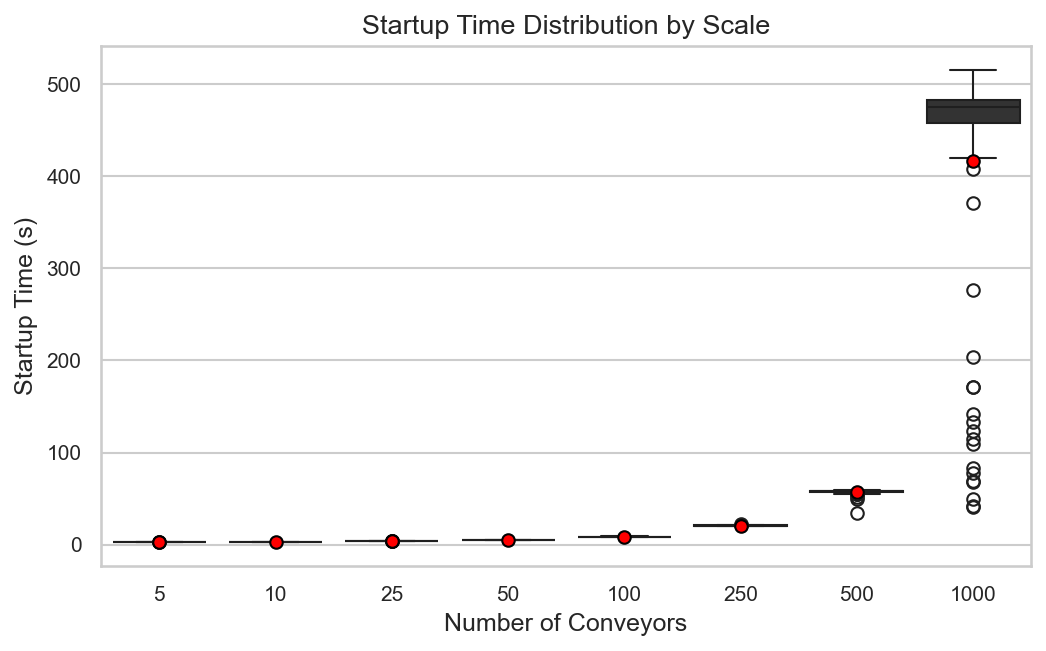

In [104]:
# 2.1 Startup Time Boxplot
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_runs, x='Conveyors', y='StartupTime_s', hue='Conveyors', legend=False, palette='Blues_d', showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black", "markersize": 6})
plt.title("Startup Time Distribution by Scale")
plt.xlabel("Number of Conveyors")
plt.ylabel("Startup Time (s)")
plt.show()


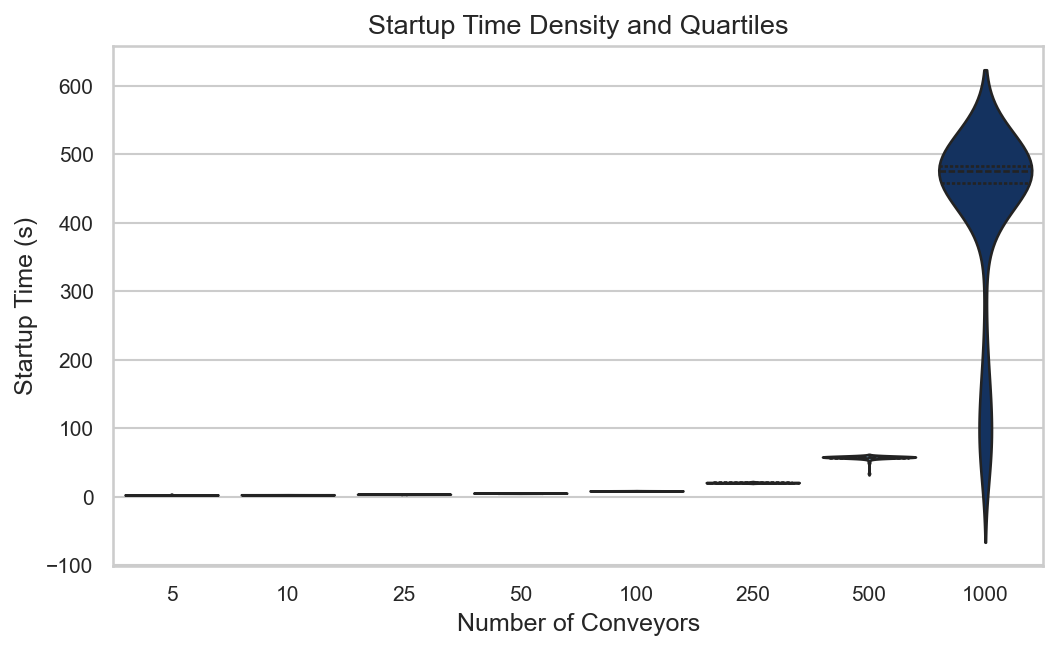

In [105]:
# 2.2 Startup Time Violin Plot
plt.figure(figsize=(8, 4.5))
sns.violinplot(data=df_runs, x='Conveyors', y='StartupTime_s', hue='Conveyors', legend=False, palette='Blues', inner="quartile")
plt.title("Startup Time Density and Quartiles")
plt.xlabel("Number of Conveyors")
plt.ylabel("Startup Time (s)")
plt.show()


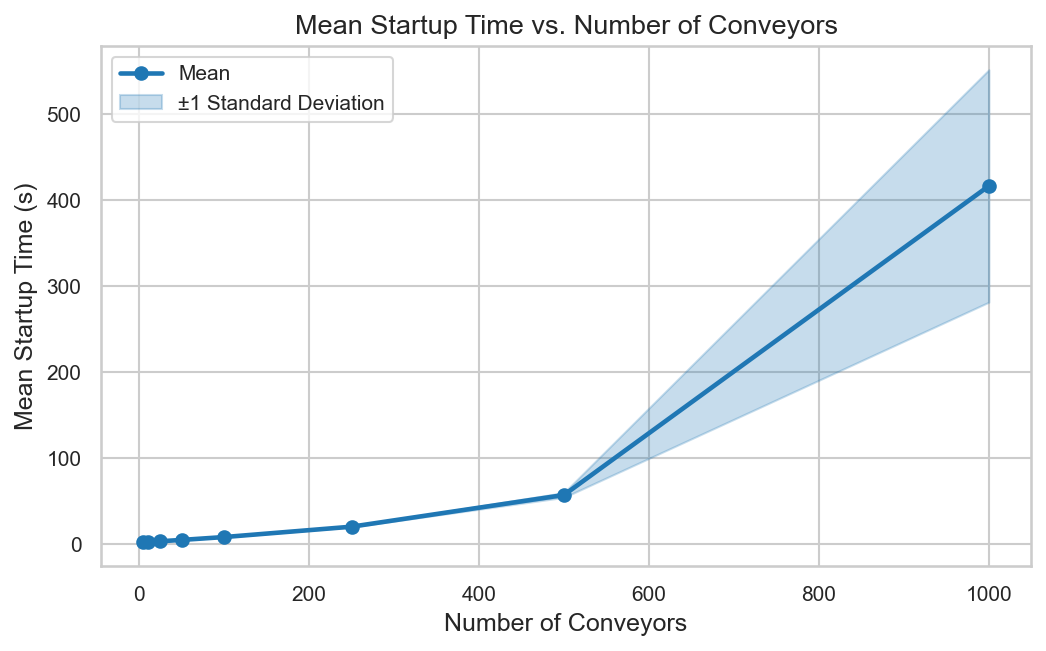

In [106]:
# 2.3 Trend Curve with Standard Deviation
startup_agg = df_runs.groupby('Conveyors')['StartupTime_s'].agg(['mean', 'std']).reset_index()
plt.figure(figsize=(8, 4.5))
plt.plot(startup_agg['Conveyors'], startup_agg['mean'], marker='o', color='#1f77b4', linewidth=2.2, label='Mean')
plt.fill_between(startup_agg['Conveyors'], 
                 startup_agg['mean'] - startup_agg['std'], 
                 startup_agg['mean'] + startup_agg['std'], 
                 alpha=0.25, color='#1f77b4', label='±1 Standard Deviation')
plt.title("Mean Startup Time vs. Number of Conveyors")
plt.xlabel("Number of Conveyors")
plt.ylabel("Mean Startup Time (s)")
plt.legend()
plt.show()


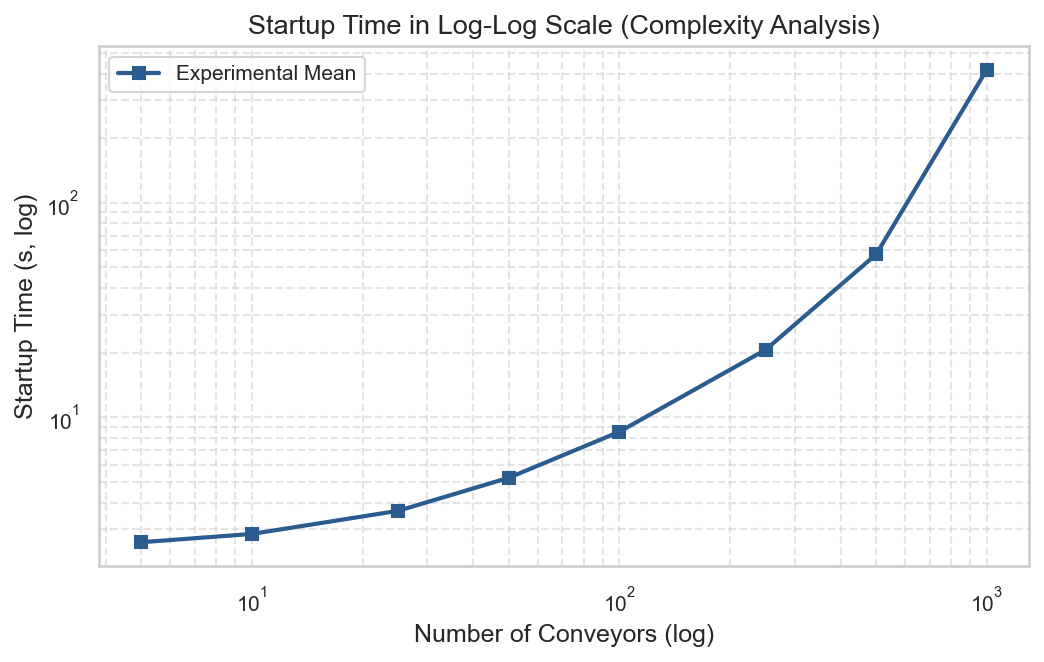

In [107]:
# 2.4 Log-Log Scale Analysis (Algorithmic Complexity)
plt.figure(figsize=(8, 4.5))
plt.plot(startup_agg['Conveyors'], startup_agg['mean'], marker='s', color='#2b5c8f', linewidth=2, label='Experimental Mean')
plt.xscale('log')
plt.yscale('log')
plt.title("Startup Time in Log-Log Scale (Complexity Analysis)")
plt.xlabel("Number of Conveyors (log)")
plt.ylabel("Startup Time (s, log)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()


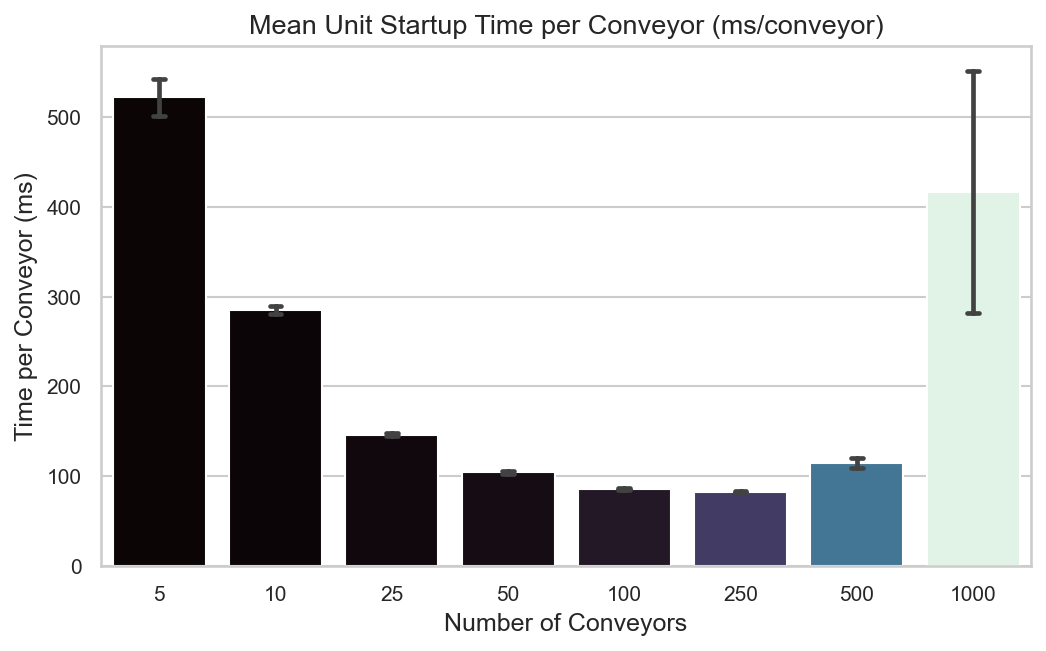

In [108]:
# 2.5 Unit Startup Cost per Conveyor
plt.figure(figsize=(8, 4.5))
sns.barplot(data=df_runs, x='Conveyors', y='Startup_per_Conveyor_ms', hue='Conveyors', legend=False, palette='mako', errorbar='sd', capsize=0.1)
plt.title("Mean Unit Startup Time per Conveyor (ms/conveyor)")
plt.xlabel("Number of Conveyors")
plt.ylabel("Time per Conveyor (ms)")
plt.show()


## 3. Fluidez de Renderização e Simulação (FPS)


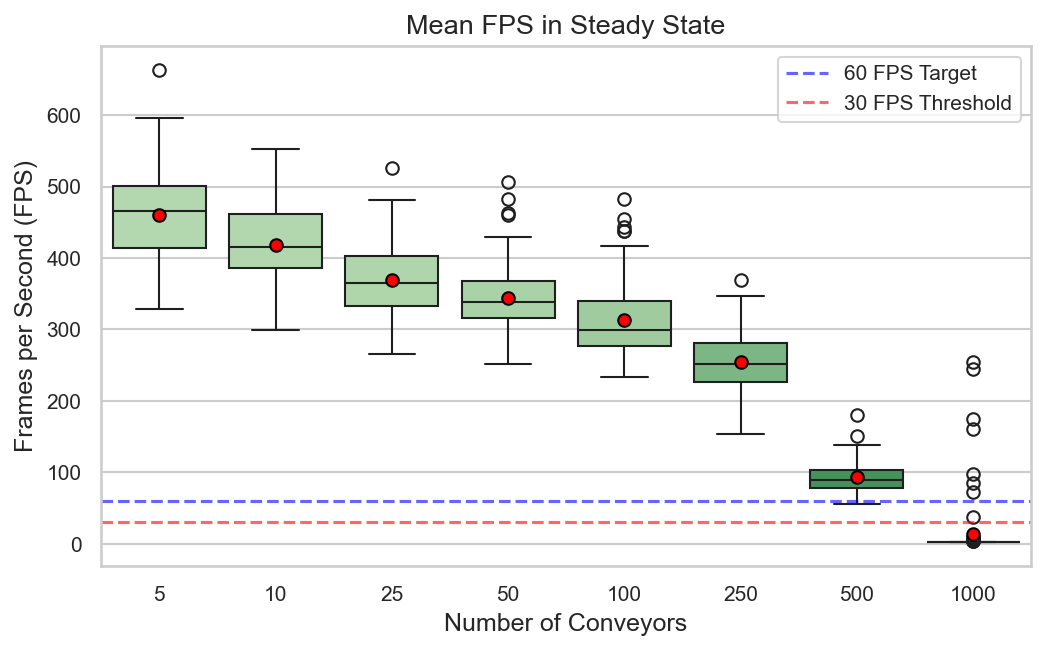

In [109]:
# 3.1 Mean FPS Boxplot
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_runs, x='Conveyors', y='FPS_Mean', hue='Conveyors', legend=False, palette='Greens_d', showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black", "markersize": 6})
plt.axhline(60, color='blue', linestyle='--', alpha=0.6, label='60 FPS Target')
plt.axhline(30, color='red', linestyle='--', alpha=0.6, label='30 FPS Threshold')
plt.title("Mean FPS in Steady State")
plt.xlabel("Number of Conveyors")
plt.ylabel("Frames per Second (FPS)")
plt.legend()
plt.show()


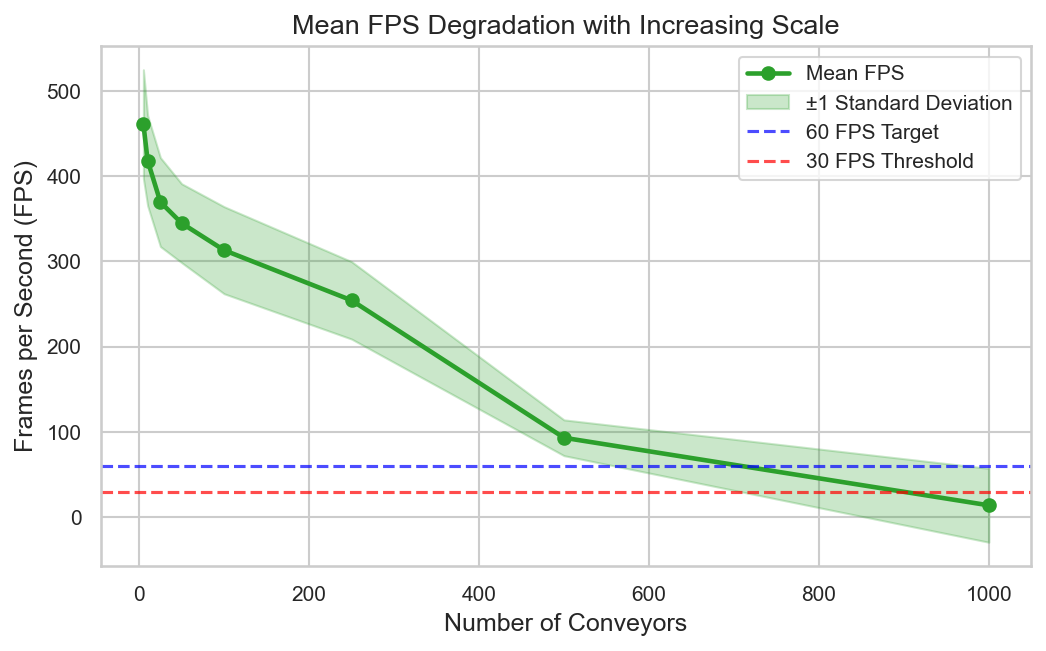

In [110]:
# 3.2 Mean FPS Degradation (Curve with Standard Deviation)
fps_agg = df_runs.groupby('Conveyors')['FPS_Mean'].agg(['mean', 'std']).reset_index()
plt.figure(figsize=(8, 4.5))
plt.plot(fps_agg['Conveyors'], fps_agg['mean'], marker='o', color='#2ca02c', linewidth=2.2, label='Mean FPS')
plt.fill_between(fps_agg['Conveyors'], 
                 fps_agg['mean'] - fps_agg['std'], 
                 fps_agg['mean'] + fps_agg['std'], 
                 alpha=0.25, color='#2ca02c', label='±1 Standard Deviation')
plt.axhline(60, color='blue', linestyle='--', alpha=0.7, label='60 FPS Target')
plt.axhline(30, color='red', linestyle='--', alpha=0.7, label='30 FPS Threshold')
plt.title("Mean FPS Degradation with Increasing Scale")
plt.xlabel("Number of Conveyors")
plt.ylabel("Frames per Second (FPS)")
plt.legend()
plt.show()


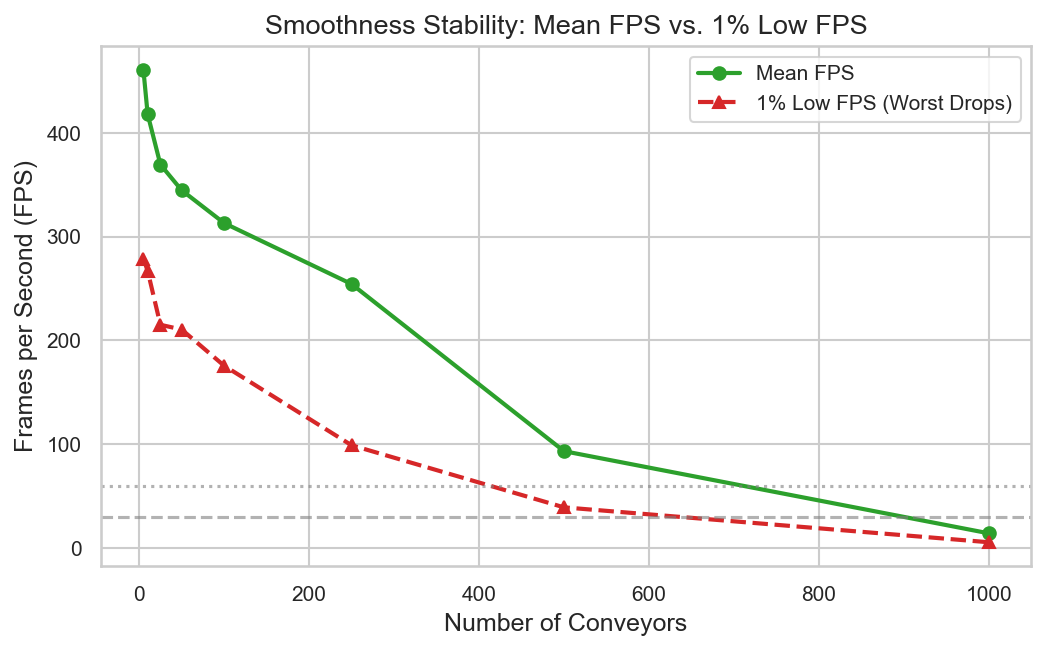

In [111]:
# 3.3 Smoothness Stability: Mean FPS vs 1% Low FPS
fps_low_agg = df_runs.groupby('Conveyors')['FPS_P01_Low'].agg(['mean']).reset_index()
plt.figure(figsize=(8, 4.5))
plt.plot(fps_agg['Conveyors'], fps_agg['mean'], marker='o', color='#2ca02c', linewidth=2, label='Mean FPS')
plt.plot(fps_low_agg['Conveyors'], fps_low_agg['mean'], marker='^', color='#d62728', linewidth=2, linestyle='--', label='1% Low FPS (Worst Drops)')
plt.axhline(60, color='gray', linestyle=':', alpha=0.6)
plt.axhline(30, color='gray', linestyle='--', alpha=0.6)
plt.title("Smoothness Stability: Mean FPS vs. 1% Low FPS")
plt.xlabel("Number of Conveyors")
plt.ylabel("Frames per Second (FPS)")
plt.legend()
plt.show()


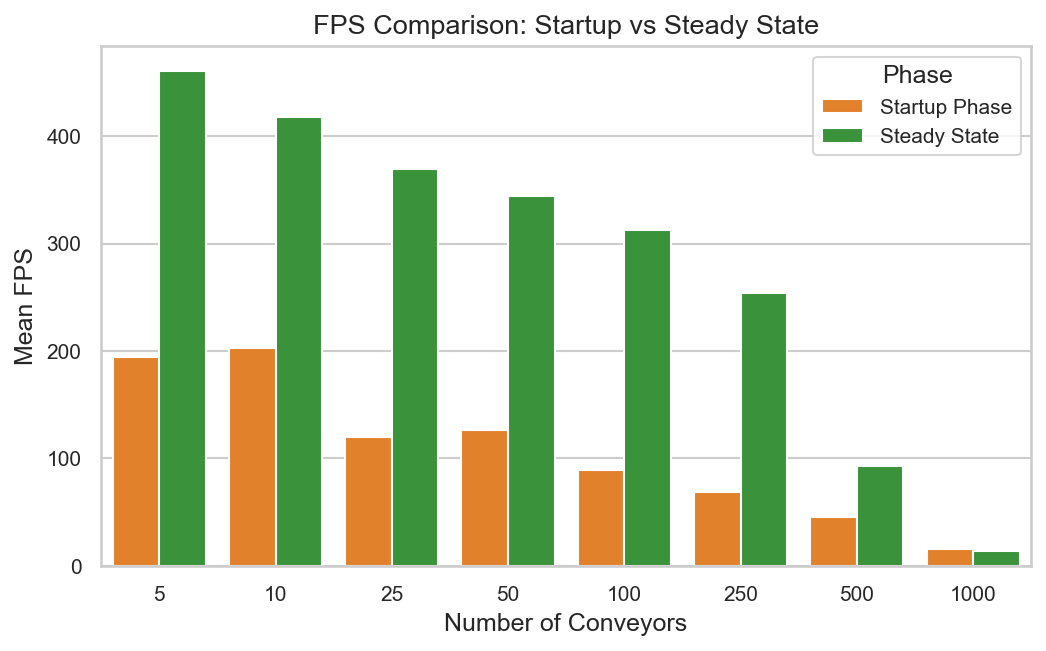

In [112]:
# 3.4 Comparison: Startup Phase FPS vs Steady State
phases_df = df_runs.groupby('Conveyors')[['FPS_Startup_Mean', 'FPS_Mean']].mean().reset_index()
phases_melted = phases_df.melt(id_vars='Conveyors', var_name='Phase', value_name='FPS')
phases_melted['Phase'] = phases_melted['Phase'].map({'FPS_Startup_Mean': 'Startup Phase', 'FPS_Mean': 'Steady State'})
plt.figure(figsize=(8, 4.5))
sns.barplot(data=phases_melted, x='Conveyors', y='FPS', hue='Phase', palette=['#ff7f0e', '#2ca02c'])
plt.title("FPS Comparison: Startup vs Steady State")
plt.xlabel("Number of Conveyors")
plt.ylabel("Mean FPS")
plt.show()


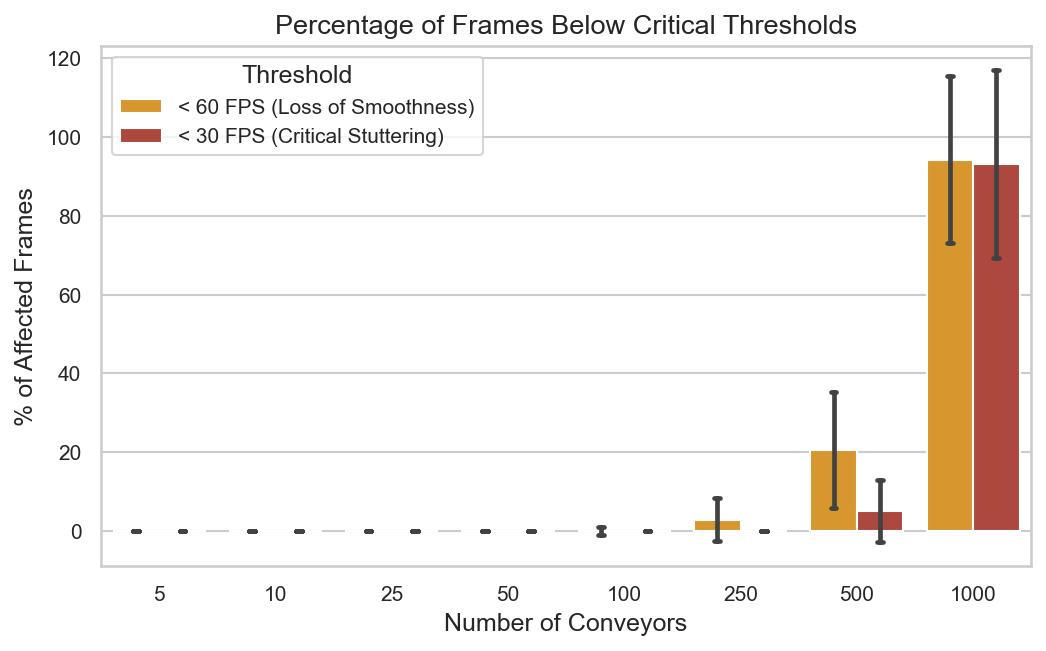

In [113]:
# 3.5 Percentage of Frames with Fluidity Loss (<60 FPS and <30 FPS)
pct_melted = df_runs.melt(id_vars=['Conveyors'], value_vars=['Pct_Frames_Below_60', 'Pct_Frames_Below_30'],
                           var_name='Threshold', value_name='Percentage')
pct_melted['Threshold'] = pct_melted['Threshold'].map({
    'Pct_Frames_Below_60': '< 60 FPS (Loss of Smoothness)',
    'Pct_Frames_Below_30': '< 30 FPS (Critical Stuttering)'
})
plt.figure(figsize=(8, 4.5))
sns.barplot(data=pct_melted, x='Conveyors', y='Percentage', hue='Threshold', palette=['#f39c12', '#c0392b'], errorbar='sd', capsize=0.1)
plt.title("Percentage of Frames Below Critical Thresholds")
plt.xlabel("Number of Conveyors")
plt.ylabel("% of Affected Frames")
plt.show()


## 4. Latência de Renderização (Frame Time em Milissegundos)


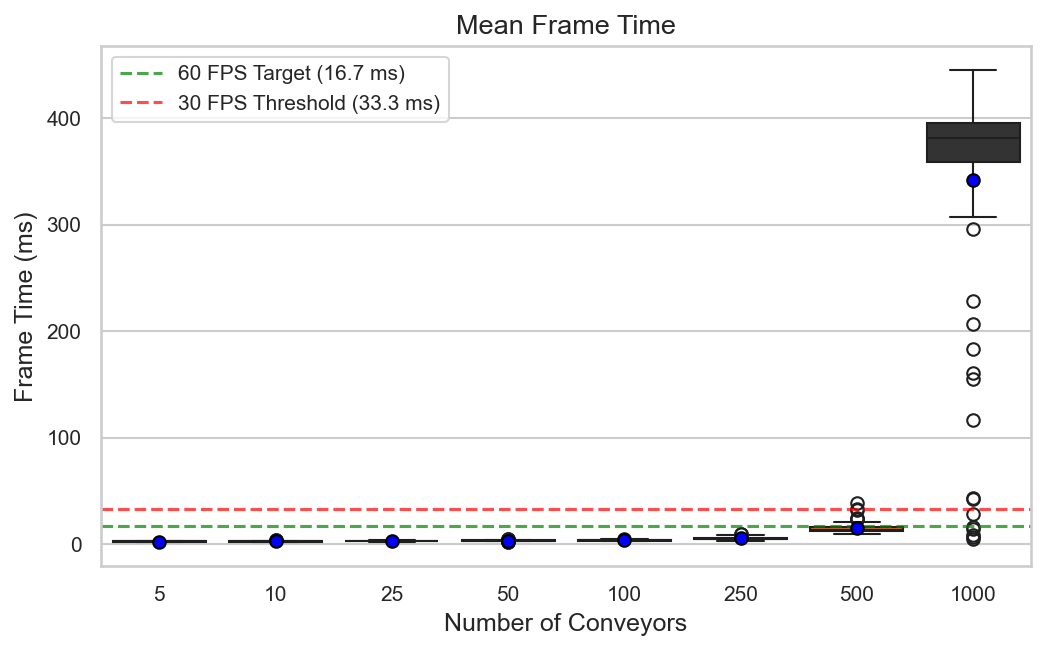

In [114]:
# 4.1 Mean Frame Time Boxplot
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_runs, x='Conveyors', y='FrameTime_Mean_ms', hue='Conveyors', legend=False, palette='Oranges_d', showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"blue", "markeredgecolor":"black", "markersize": 6})
plt.axhline(16.67, color='green', linestyle='--', alpha=0.7, label='60 FPS Target (16.7 ms)')
plt.axhline(33.33, color='red', linestyle='--', alpha=0.7, label='30 FPS Threshold (33.3 ms)')
plt.title("Mean Frame Time")
plt.xlabel("Number of Conveyors")
plt.ylabel("Frame Time (ms)")
plt.legend()
plt.show()


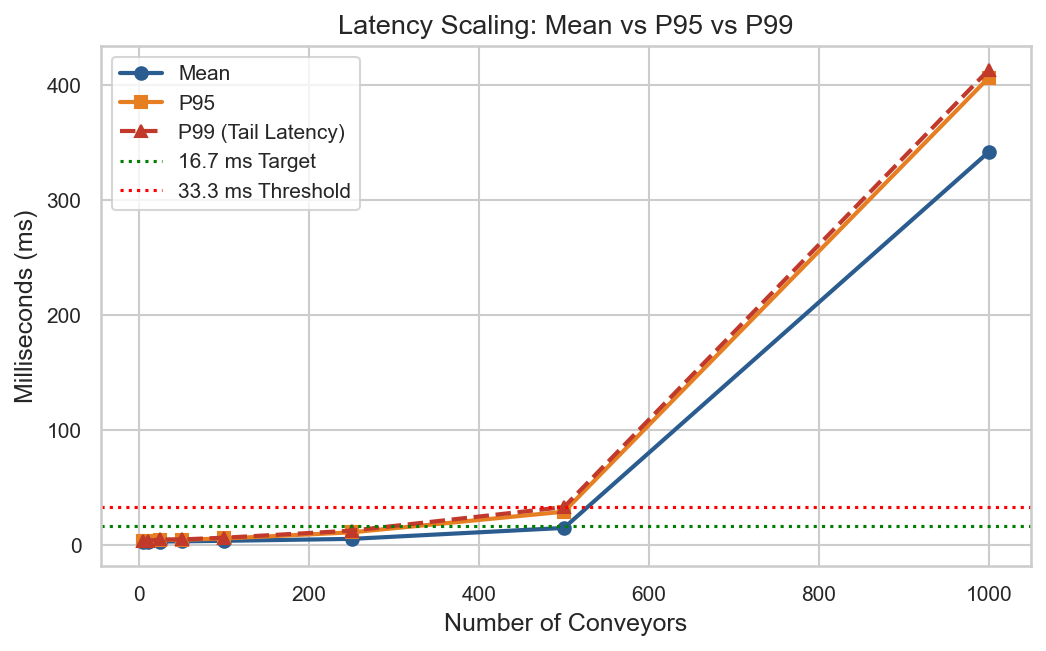

In [115]:
# 4.2 Tail Latency: P95 and P99 Percentiles
lat_agg = df_runs.groupby('Conveyors').agg({
    'FrameTime_Mean_ms': 'mean',
    'FrameTime_P95_ms': 'mean',
    'FrameTime_P99_ms': 'mean'
}).reset_index()

plt.figure(figsize=(8, 4.5))
plt.plot(lat_agg['Conveyors'], lat_agg['FrameTime_Mean_ms'], marker='o', color='#2b5c8f', linewidth=2, label='Mean')
plt.plot(lat_agg['Conveyors'], lat_agg['FrameTime_P95_ms'], marker='s', color='#e67e22', linewidth=2, label='P95')
plt.plot(lat_agg['Conveyors'], lat_agg['FrameTime_P99_ms'], marker='^', color='#c0392b', linewidth=2, linestyle='--', label='P99 (Tail Latency)')
plt.axhline(16.67, color='green', linestyle=':', label='16.7 ms Target')
plt.axhline(33.33, color='red', linestyle=':', label='33.3 ms Threshold')
plt.title("Latency Scaling: Mean vs P95 vs P99")
plt.xlabel("Number of Conveyors")
plt.ylabel("Milliseconds (ms)")
plt.legend()
plt.show()


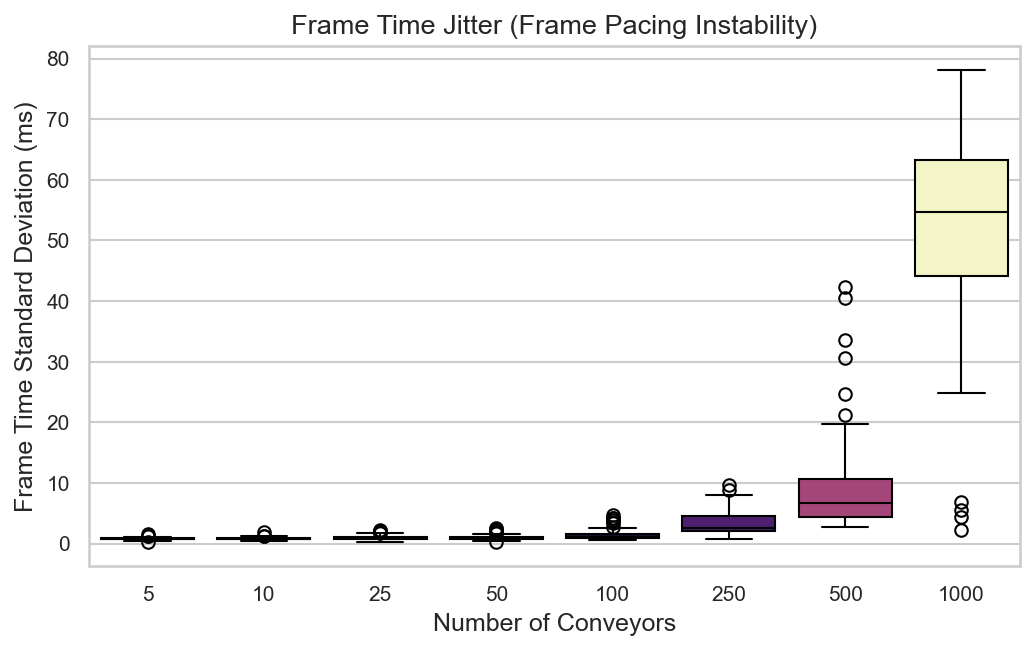

In [116]:
# 4.3 Frame Time Jitter (Standard Deviation per Run)
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_runs, x='Conveyors', y='FrameTime_Std_ms', hue='Conveyors', legend=False, palette='magma')
plt.title("Frame Time Jitter (Frame Pacing Instability)")
plt.xlabel("Number of Conveyors")
plt.ylabel("Frame Time Standard Deviation (ms)")
plt.show()


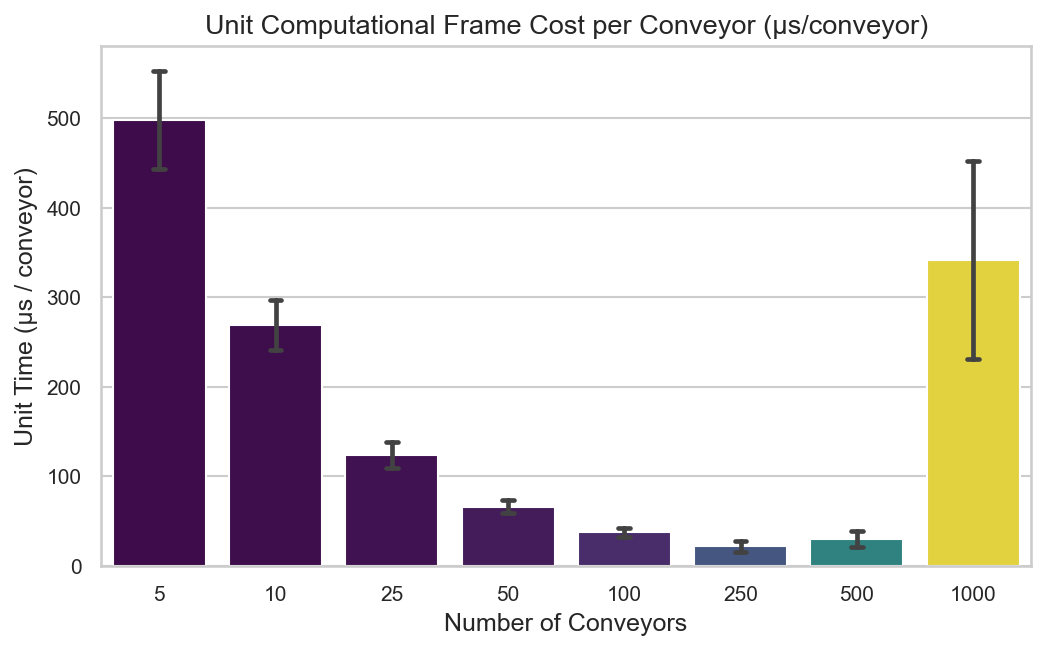

In [117]:
# 4.4 Unit Computational Frame Cost per Conveyor (µs/conveyor)
plt.figure(figsize=(8, 4.5))
sns.barplot(data=df_runs, x='Conveyors', y='FrameTime_per_Conveyor_us', hue='Conveyors', legend=False, palette='viridis', errorbar='sd', capsize=0.1)
plt.title("Unit Computational Frame Cost per Conveyor (µs/conveyor)")
plt.xlabel("Number of Conveyors")
plt.ylabel("Unit Time (µs / conveyor)")
plt.show()


## 5. Consumo de Memória RAM (Heap Gerido vs Total Reservada)


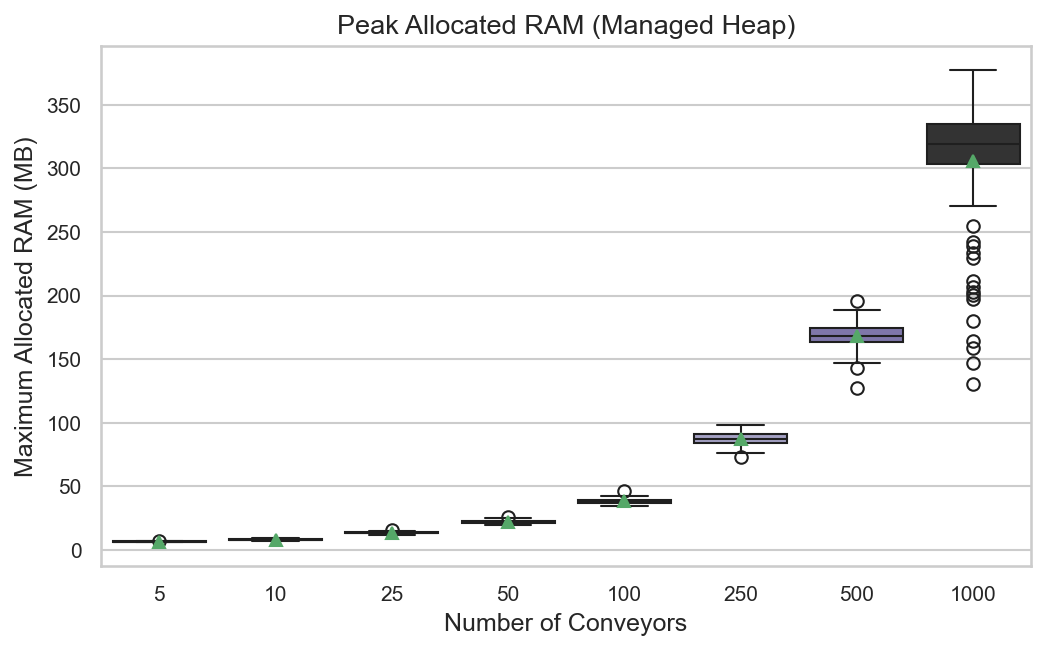

In [118]:
# 5.1 Boxplot: Maximum Allocated RAM (Managed Heap)
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df_runs, x='Conveyors', y='RAM_Alloc_Max_MB', hue='Conveyors', legend=False, palette='Purples_d', showmeans=True)
plt.title("Peak Allocated RAM (Managed Heap)")
plt.xlabel("Number of Conveyors")
plt.ylabel("Maximum Allocated RAM (MB)")
plt.show()


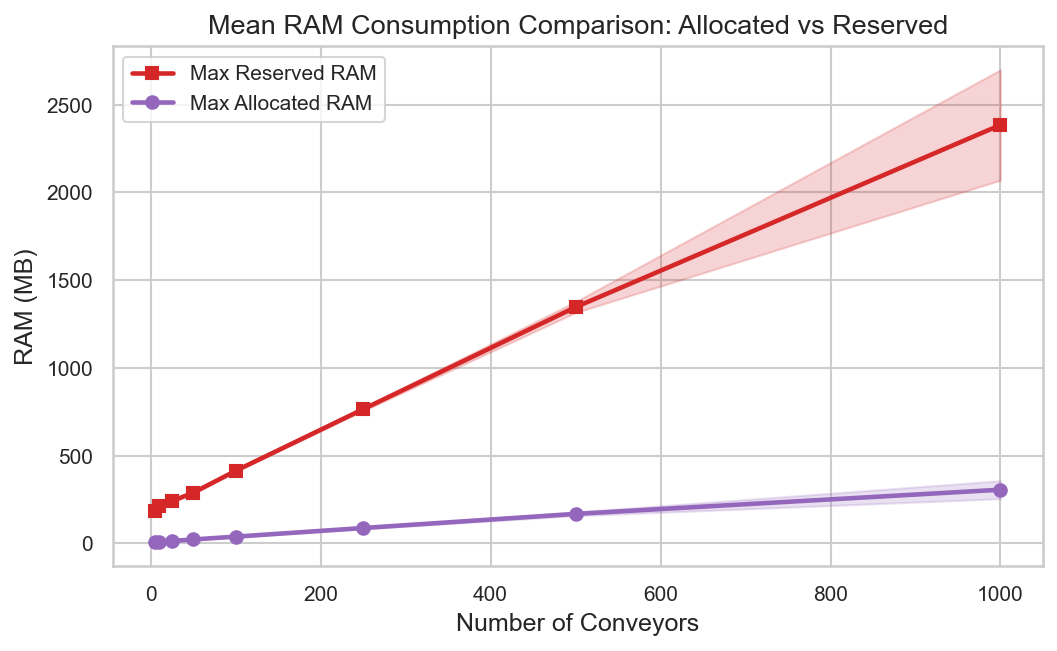

In [119]:
# 5.2 Comparative Curves: Allocated RAM vs Total Reserved RAM
ram_agg = df_runs.groupby('Conveyors').agg({
    'RAM_Alloc_Max_MB': ['mean', 'std'],
    'RAM_Reserved_Max_MB': ['mean', 'std']
}).reset_index()

plt.figure(figsize=(8, 4.5))
plt.plot(ram_agg['Conveyors'], ram_agg[('RAM_Reserved_Max_MB', 'mean')], marker='s', color='#d62728', linewidth=2.2, label='Max Reserved RAM')
plt.fill_between(ram_agg['Conveyors'], 
                 ram_agg[('RAM_Reserved_Max_MB', 'mean')] - ram_agg[('RAM_Reserved_Max_MB', 'std')], 
                 ram_agg[('RAM_Reserved_Max_MB', 'mean')] + ram_agg[('RAM_Reserved_Max_MB', 'std')], 
                 alpha=0.2, color='#d62728')
plt.plot(ram_agg['Conveyors'], ram_agg[('RAM_Alloc_Max_MB', 'mean')], marker='o', color='#9467bd', linewidth=2.2, label='Max Allocated RAM')
plt.fill_between(ram_agg['Conveyors'], 
                 ram_agg[('RAM_Alloc_Max_MB', 'mean')] - ram_agg[('RAM_Alloc_Max_MB', 'std')], 
                 ram_agg[('RAM_Alloc_Max_MB', 'mean')] + ram_agg[('RAM_Alloc_Max_MB', 'std')], 
                 alpha=0.2, color='#9467bd')
plt.title("Mean RAM Consumption Comparison: Allocated vs Reserved")
plt.xlabel("Number of Conveyors")
plt.ylabel("RAM (MB)")
plt.legend()
plt.show()


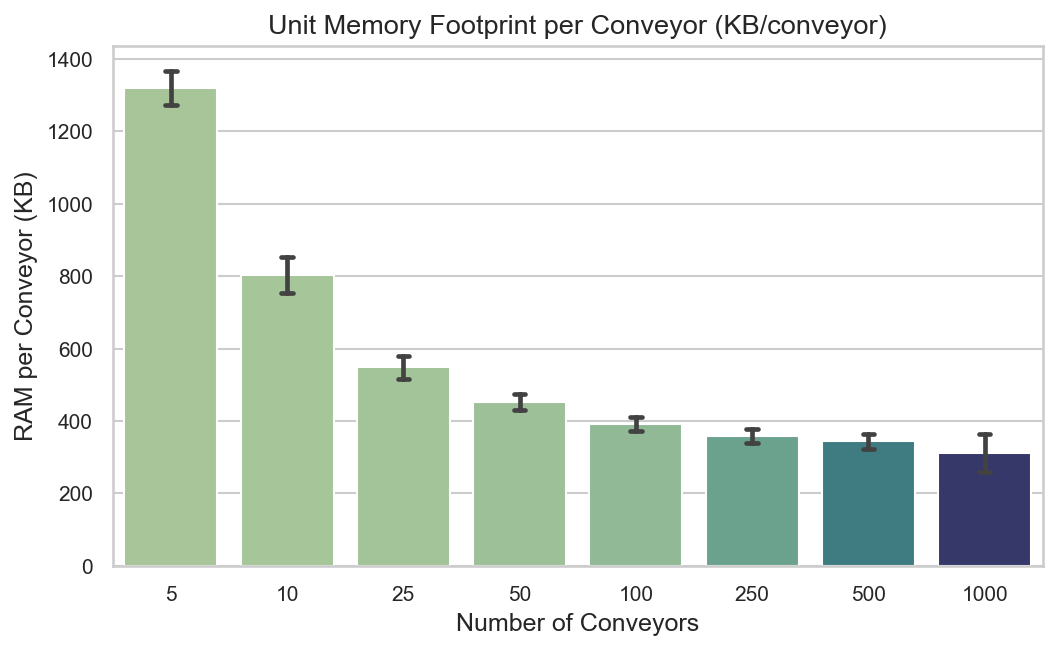

In [120]:
# 5.3 Unit Memory Footprint per Conveyor (KB/conveyor)
plt.figure(figsize=(8, 4.5))
sns.barplot(data=df_runs, x='Conveyors', y='RAM_Alloc_per_Conveyor_KB', hue='Conveyors', legend=False, palette='crest', errorbar='sd', capsize=0.1)
plt.title("Unit Memory Footprint per Conveyor (KB/conveyor)")
plt.xlabel("Number of Conveyors")
plt.ylabel("RAM per Conveyor (KB)")
plt.show()


## 6. Evolução Temporal da Simulação ao Longo dos Segundos


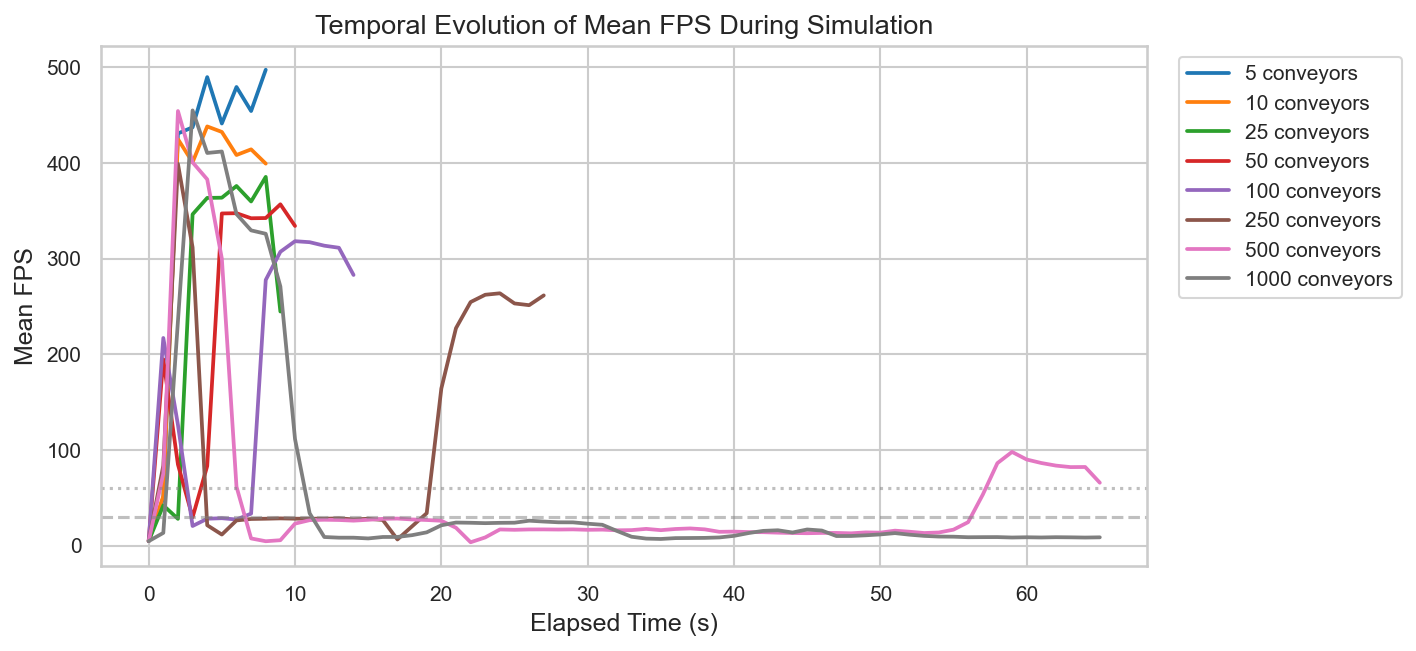

In [121]:
conveyors_order = sorted(df_runs['Conveyors'].unique())
colors = sns.color_palette("tab10", len(conveyors_order))
df_ts_filt = df_ts[df_ts['Time_bin'] <= 65]
ts_mean = df_ts_filt.groupby(['Conveyors', 'Time_bin']).mean().reset_index()

# 6.1 FPS Time Series
plt.figure(figsize=(9, 4.5))
for idx, c in enumerate(conveyors_order):
    sub = ts_mean[ts_mean['Conveyors'] == c]
    plt.plot(sub['Time_bin'], sub['FPS'], label=f"{c} conveyors", color=colors[idx], linewidth=1.8)
plt.axhline(60, color='gray', linestyle=':', alpha=0.5)
plt.axhline(30, color='gray', linestyle='--', alpha=0.5)
plt.title("Temporal Evolution of Mean FPS During Simulation")
plt.xlabel("Elapsed Time (s)")
plt.ylabel("Mean FPS")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()


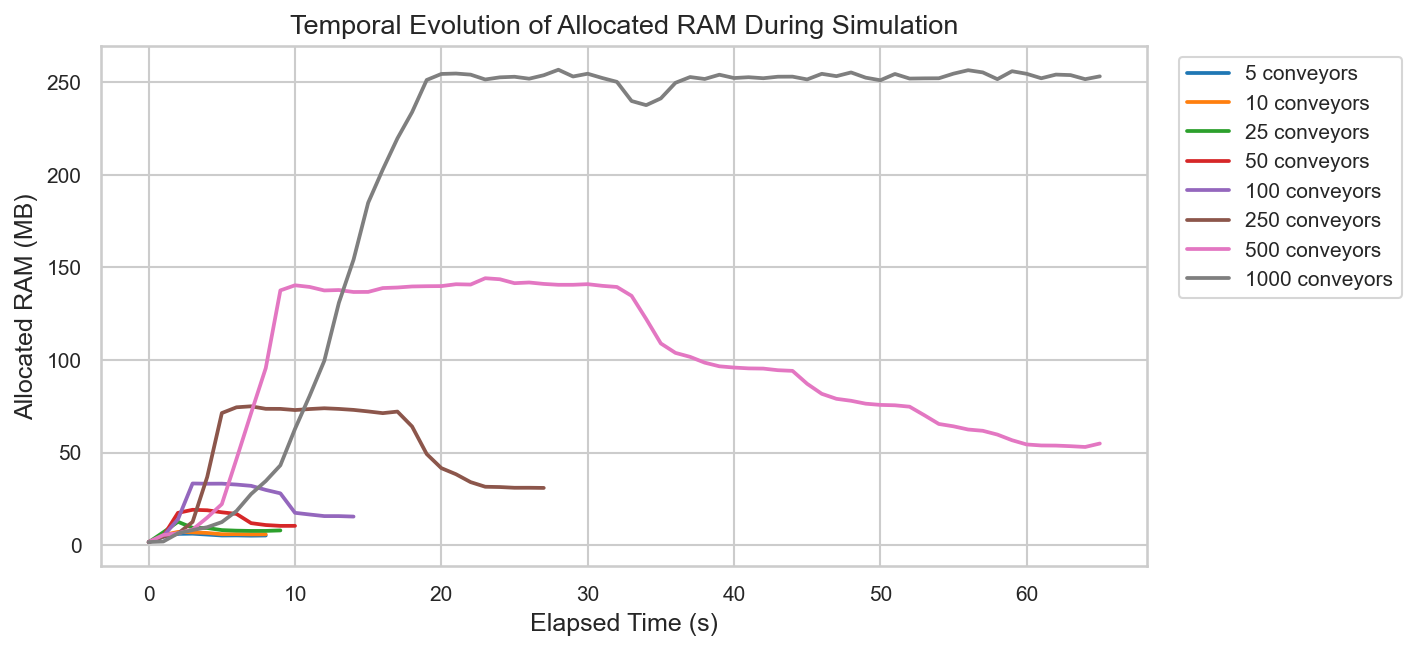

In [122]:
# 6.2 Allocated RAM Time Series
plt.figure(figsize=(9, 4.5))
for idx, c in enumerate(conveyors_order):
    sub = ts_mean[ts_mean['Conveyors'] == c]
    plt.plot(sub['Time_bin'], sub['RAM_Allocated_MB'], label=f"{c} conveyors", color=colors[idx], linewidth=1.8)
plt.title("Temporal Evolution of Allocated RAM During Simulation")
plt.xlabel("Elapsed Time (s)")
plt.ylabel("Allocated RAM (MB)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()


## 7. Análise Estatística Avançada e Correlações


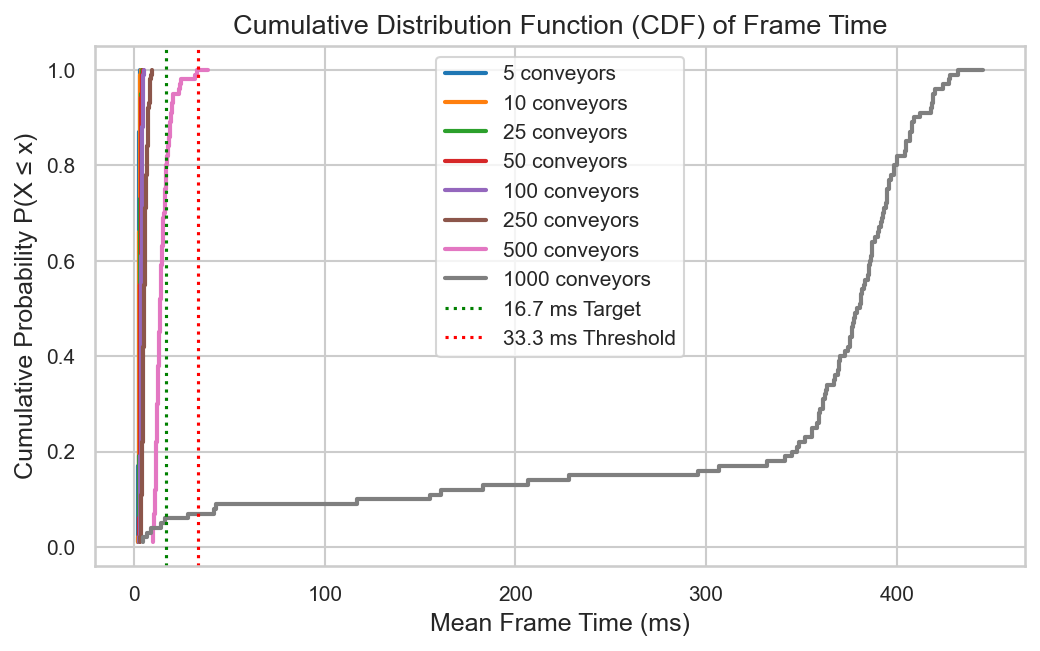

In [123]:
# 7.1 Empirical Cumulative Distribution Function (CDF) of Frame Time
plt.figure(figsize=(8, 4.5))
for idx, c in enumerate(conveyors_order):
    vals = np.sort(df_runs[df_runs['Conveyors'] == c]['FrameTime_Mean_ms'].dropna())
    if len(vals) > 0:
        y = np.arange(1, len(vals) + 1) / len(vals)
        plt.step(vals, y, label=f"{c} conveyors", color=colors[idx], linewidth=2)
plt.axvline(16.67, color='green', linestyle=':', label='16.7 ms Target')
plt.axvline(33.33, color='red', linestyle=':', label='33.3 ms Threshold')
plt.title("Cumulative Distribution Function (CDF) of Frame Time")
plt.xlabel("Mean Frame Time (ms)")
plt.ylabel("Cumulative Probability P(X ≤ x)")
plt.legend()
plt.show()


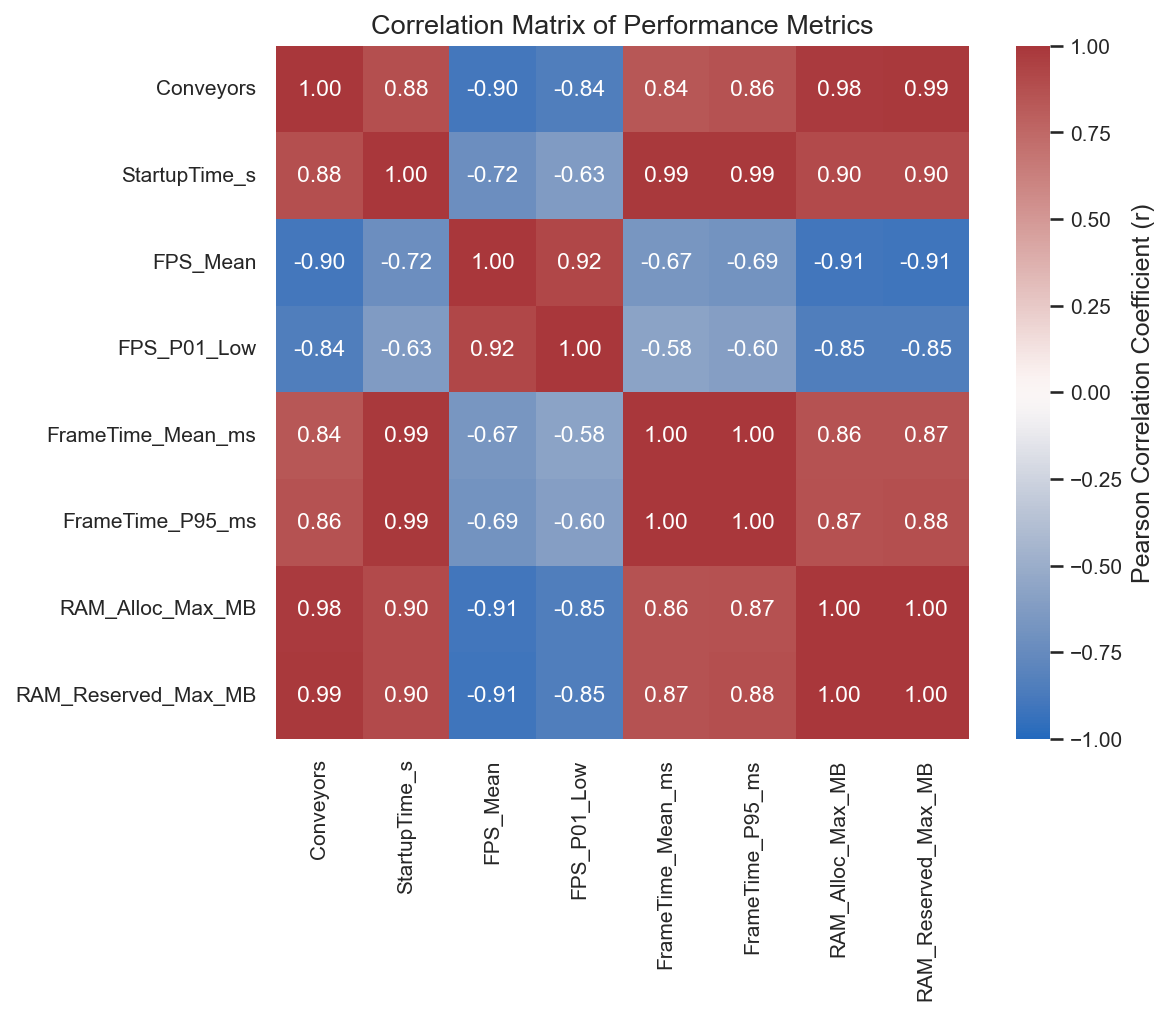

In [124]:
# 7.2 Pearson Linear Correlation Matrix
corr_cols = [
    'Conveyors', 'StartupTime_s', 'FPS_Mean', 'FPS_P01_Low',
    'FrameTime_Mean_ms', 'FrameTime_P95_ms', 'RAM_Alloc_Max_MB', 'RAM_Reserved_Max_MB'
]
plt.figure(figsize=(8, 6))
sns.heatmap(df_runs[corr_cols].corr(), annot=True, fmt=".2f", cmap='vlag', vmin=-1, vmax=1, square=True,
            cbar_kws={'label': 'Pearson Correlation Coefficient (r)'})
plt.title("Correlation Matrix of Performance Metrics")
plt.show()


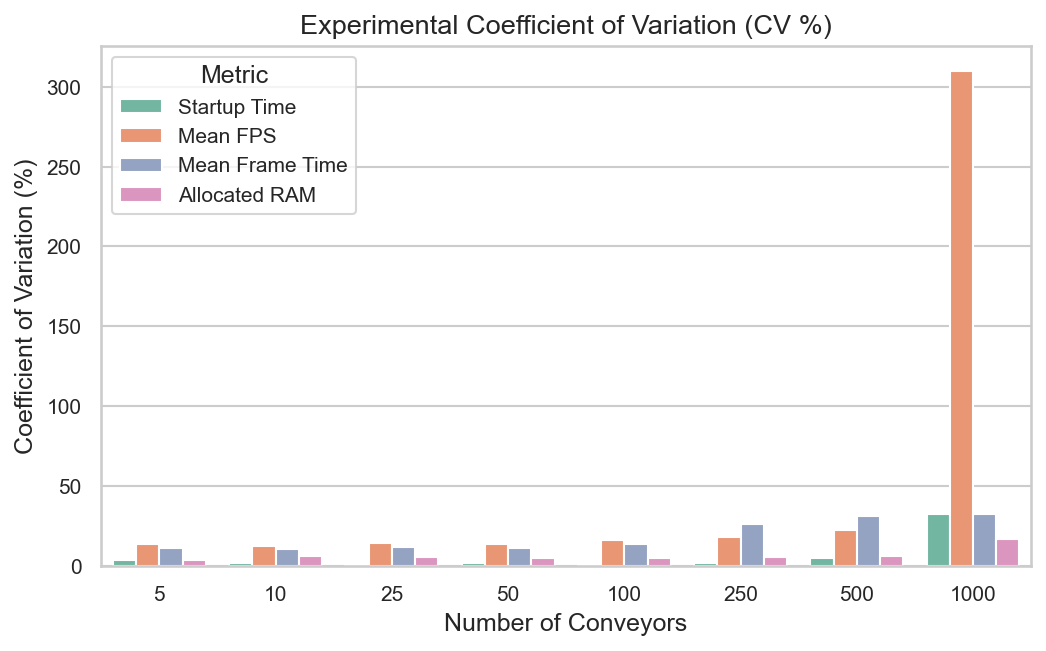

In [125]:
# 7.3 Coefficient of Variation (CV %): Consistency Verification across 100 Runs
stats_cv = df_runs.groupby('Conveyors').agg({
    'StartupTime_s': lambda x: (x.std() / x.mean()) * 100.0,
    'FPS_Mean': lambda x: (x.std() / x.mean()) * 100.0,
    'FrameTime_Mean_ms': lambda x: (x.std() / x.mean()) * 100.0,
    'RAM_Alloc_Max_MB': lambda x: (x.std() / x.mean()) * 100.0
}).reset_index()

cv_melted = stats_cv.melt(id_vars=['Conveyors'], var_name='Metric', value_name='CV_%')
cv_melted['Metric'] = cv_melted['Metric'].map({
    'StartupTime_s': 'Startup Time',
    'FPS_Mean': 'Mean FPS',
    'FrameTime_Mean_ms': 'Mean Frame Time',
    'RAM_Alloc_Max_MB': 'Allocated RAM'
})
plt.figure(figsize=(8, 4.5))
sns.barplot(data=cv_melted, x='Conveyors', y='CV_%', hue='Metric', palette='Set2')
plt.title("Experimental Coefficient of Variation (CV %)")
plt.xlabel("Number of Conveyors")
plt.ylabel("Coefficient of Variation (%)")
plt.show()
